# Tarea 1: WAPE y bias del pronóstico de demanda
Evalúa el pronóstico original por centro de distribución (CD) y por horizonte (D+1 a D+4). Toda la lógica vive en `src/logforecast` (`io`, `quality`, `diagnostics`, `plots`); el notebook solo llama funciones y muestra resultados.

**Orden:**
1. Carga y calidad de los datos.
2. EDA: pronóstico vs real, bias móvil y real por canal.
3. WAPE y bias por CD y horizonte.
4. Respuestas a las preguntas 1 y 2.

**Definiciones:** `WAPE = Σ|real − pronóstico| / Σ real` y `Bias = (Σ real − Σ pronóstico) / Σ real`. Bias positivo = el pronóstico **subestima**; negativo = **sobreestima**. La tolerancia para llamar a un CD "sin sesgo" es `LF_BIAS_TOLERANCE` (5 % por defecto).

In [1]:
from logforecast import diagnostics, io, plots
from logforecast.config import Settings
from logforecast.quality import check_quality

S = Settings.from_env()
orders, fc, cap, plan = io.load_orders(S), io.load_forecasts(S), io.load_capacity(S), io.load_plan(S)

In [2]:
frame = diagnostics.build_eval_frame(orders, fc)

## 1. Datos y calidad
Tamaño de cada tabla (pedidos, pronósticos, capacidad, plan), primeras filas y chequeos de calidad.

In [3]:
len(orders), len(fc), len(cap), len(plan)

(1080, 1380, 360, 739)

In [4]:
orders.head()

,centro_distribucion,fecha_despacho,unidades_reales,canal_venta
0,CD_NORTE,2026-01-01,2234.68,PORTAL_WEB
1,CD_NORTE,2026-01-01,1310.74,AGENTE_COMERCIAL
2,CD_NORTE,2026-01-01,266.64,ATENCION_TELEFONICA
3,CD_SUR,2026-01-01,1452.21,PORTAL_WEB
4,CD_SUR,2026-01-01,131.84,AGENTE_COMERCIAL


In [5]:
fc.head()

,centro_distribucion,fecha_emision,fecha_despacho,horizonte,unidades_pronosticadas
0,CD_CENTRO,2026-01-01,2026-01-02,D+1,2291.79
1,CD_CENTRO,2026-01-02,2026-01-03,D+1,2038.75
2,CD_CENTRO,2026-01-01,2026-01-03,D+2,1666.19
3,CD_CENTRO,2026-01-03,2026-01-04,D+1,1568.46
4,CD_CENTRO,2026-01-02,2026-01-04,D+2,1618.32


In [6]:
cap.head()

,centro_distribucion,fecha,capacidad_maxima_unidades
0,CD_NORTE,2026-01-01,3600.0
1,CD_SUR,2026-01-01,2640.0
2,CD_CENTRO,2026-01-01,1800.0
3,CD_ESTE,2026-01-01,960.0
4,CD_OESTE,2026-01-01,600.0


In [7]:
plan.head()

,cliente_id,centro_distribucion,canal_venta,fecha_plan,unidades_plan,fecha_compra_real,unidades_reales,fuera_de_plan
0,CLIENTE_001,CD_NORTE,PORTAL_WEB,2026-01-02,359.88,2026-01-04,419.58,1
1,CLIENTE_001,CD_NORTE,PORTAL_WEB,2026-01-09,219.29,2026-01-09,203.44,0
2,CLIENTE_001,CD_NORTE,PORTAL_WEB,2026-01-16,320.98,2026-01-20,379.57,1
3,CLIENTE_001,CD_NORTE,PORTAL_WEB,2026-01-23,278.32,2026-01-23,311.57,0
4,CLIENTE_001,CD_NORTE,PORTAL_WEB,2026-01-30,301.55,2026-01-30,308.49,0


In [8]:
check_quality(orders, fc, cap, plan).sort_values("dataset")

,dataset,check,valor,ok
16,capacity,dias_cd_sobre_capacidad,13.00,False
4,capacity,nulos_totales,0.00,True
5,capacity,filas_duplicadas,0.00,True
12,forecasts,sin_real_asociado,0.00,True
2,forecasts,nulos_totales,0.00,True
3,forecasts,filas_duplicadas,0.00,True
11,forecasts,horizonte_incoherente,0.00,True
9,forecasts,pronostico_<=0,0.00,True
10,orders,dias_faltantes_max_por_cd,0.00,True
0,orders,nulos_totales,0.00,True


## 2. EDA: pronóstico vs real
Pronóstico y real por CD en el tiempo, bias móvil de 7 días y real por canal de venta (D+1).

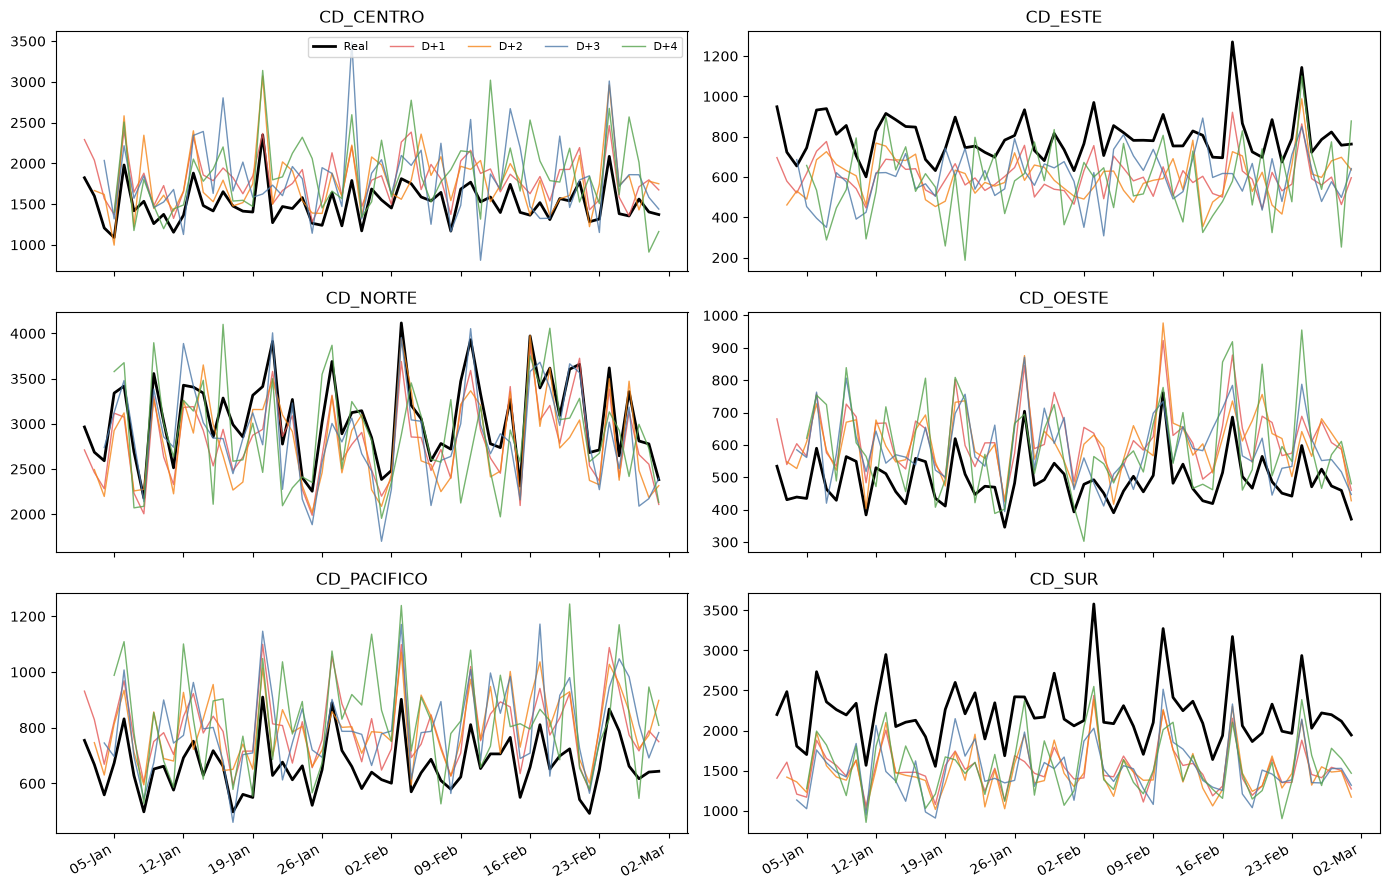

In [9]:
plots.plot_forecast_vs_real(frame)

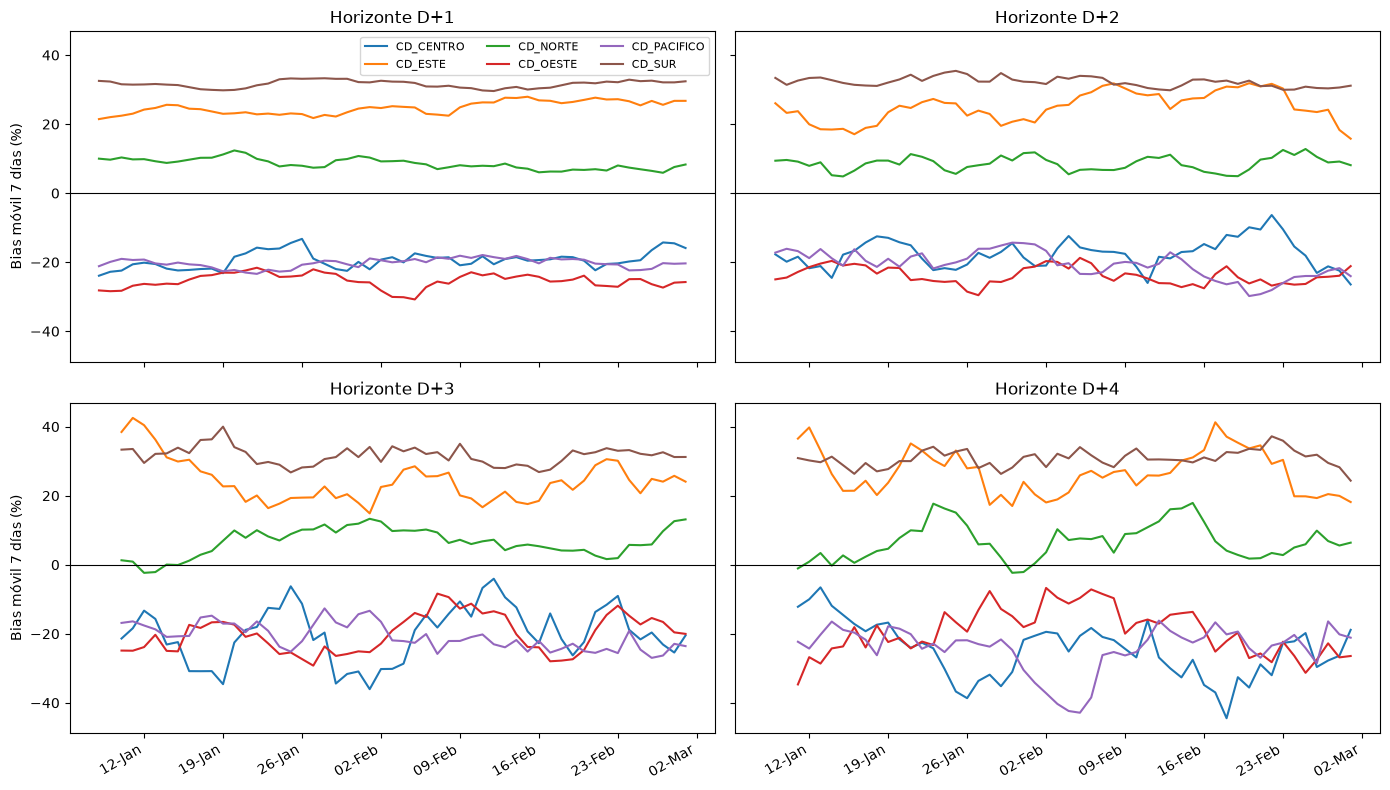

In [10]:
plots.plot_bias_rolling(frame)

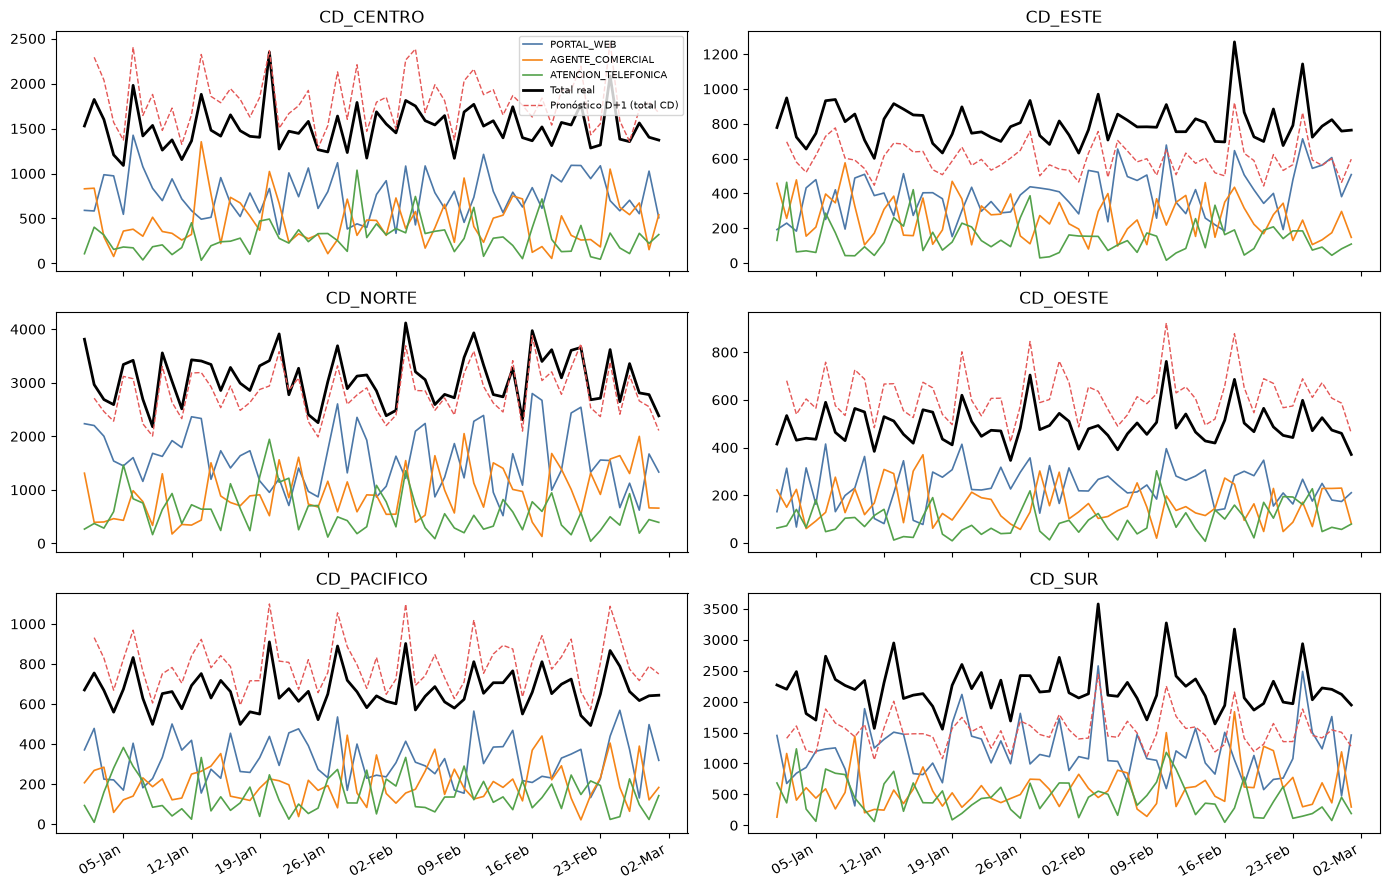

In [11]:
plots.plot_real_by_channel(orders, fc, "D+1")

## 3. WAPE y bias por CD y horizonte

In [12]:
display(diagnostics.classify_bias(diagnostics.error_by_cd(frame), S.bias_tolerance))
display(diagnostics.error_by_horizon(frame))
diagnostics.error_by_cd_horizon(frame).pivot(index='centro_distribucion', columns='horizonte', values='wape')

,centro_distribucion,wape,bias,n,tendencia
0,CD_CENTRO,0.232828,-0.202149,230.0,sobreestima
1,CD_ESTE,0.258609,0.252978,230.0,subestima
2,CD_NORTE,0.098169,0.074733,230.0,subestima
3,CD_OESTE,0.239037,-0.226615,230.0,sobreestima
4,CD_PACIFICO,0.221526,-0.215801,230.0,sobreestima
5,CD_SUR,0.315566,0.315566,230.0,subestima


,horizonte,wape,bias,n
0,D+1,0.197717,0.069390,354.0
1,D+2,0.202979,0.075555,348.0
2,D+3,0.208471,0.063995,342.0
3,D+4,0.225290,0.052406,336.0


horizonte,D+1,D+2,D+3,D+4
centro_distribucion,,,,
CD_CENTRO,0.195871,0.194914,0.266645,0.276684
CD_ESTE,0.247837,0.246684,0.254267,0.286640
CD_NORTE,0.088391,0.100630,0.085413,0.118826
CD_OESTE,0.256020,0.240697,0.218671,0.240165
CD_PACIFICO,0.202721,0.210765,0.215940,0.258120
CD_SUR,0.317313,0.323316,0.318536,0.302698


**Control de comparabilidad entre horizontes:** cada horizonte evalúa un conjunto algo distinto de fechas (las primeras fechas no tienen D+4). Se recalcula el WAPE solo con fechas comunes a los 4 horizontes.

In [13]:
diagnostics.horizon_wape_common_dates(frame)

,horizonte,wape_todas,n_todas,wape_comunes,n_comunes,dif_pp
0,D+1,0.197717,354.0,0.196155,336.0,-0.156190
1,D+2,0.202979,348.0,0.202773,336.0,-0.020671
2,D+3,0.208471,342.0,0.207460,336.0,-0.101146
3,D+4,0.225290,336.0,0.225290,336.0,0.000000


## 4. Conclusiones
### Pregunta 1: ¿Qué centros subestiman y cuáles sobreestiman la demanda?

Según la tabla de WAPE y Bias por CD, los 6 centros tienen un sesgo sistemático, 3 hacia cada lado:

- **Subestiman la demanda (bias > 0):** CD_SUR (+31,6%), CD_ESTE (+25,3%) y CD_NORTE (+7,5%).
- **Sobreestiman la demanda (bias < 0):** CD_OESTE (−22,7%), CD_PACIFICO (−21,6%) y CD_CENTRO (−20,2%).

**Consistencia del sesgo**
- **En el tiempo:** el bias móvil de 7 días no cruza el cero en ningún CD entre enero y febrero.
- **En los 4 horizontes:** el signo del bias se mantiene de D+1 a D+4 en cada CD.
- **Fila por fila:** CD_SUR subestima en el 100% de las filas y CD_ESTE en el 95%. CD_CENTRO, CD_OESTE y CD_PACIFICO sobreestiman en el 89–95%.

**Conclusiones**
- En 5 de los 6 CDs el WAPE es casi igual al valor absoluto del bias, por lo que el error es casi todo sistemático y, por lo tanto, corregible.
- CD_NORTE es el de mejor pronóstico (WAPE 9,8%); su bias es pequeño pero de signo consistente.
- El bias global (+6,5%) enmascara sesgos opuestos de ±20–30% entre CDs. Por eso la evaluación y la corrección deben hacerse por CD y no con una métrica global.

### Pregunta 2: ¿Cómo se degrada el WAPE de D+1 a D+4?

Según la tabla de error por horizonte, la degradación global es moderada y no lineal:

- **Global:** el WAPE pasa de 19,8% (D+1) a 20,3% (D+2), 20,8% (D+3) y 22,5% (D+4), es decir, +2,8 pp en total (~14% relativo). De D+1 a D+3 sube ~0,5 pp por día; el salto mayor está entre D+3 y D+4 (+1,7 pp).

**Por CD el patrón es heterogéneo** (tabla CD × horizonte):
- **Se degradan claramente:** CD_CENTRO (19,6% → 27,7%, con salto en D+3), CD_PACIFICO (20,3% → 25,8%, gradual) y CD_ESTE (24,8% → 28,7%, con salto en D+4).
- **Se degrada poco y no de forma monótona:** CD_NORTE (8,8% → 11,9%; D+3 es menor que D+2).
- **No se degradan:** CD_SUR (31,7% → 30,3%) y CD_OESTE (25,6% → 24,0%, con mínimo en D+3).

**Conclusiones**
- El horizonte pesa mucho menos que el CD: la diferencia entre D+1 y D+4 (~3 pp) es pequeña frente a la diferencia entre CDs (9,8% a 31,6%).
- En CD_SUR y CD_OESTE el error lo domina el sesgo sistemático (WAPE ≈ |bias|), que no depende de la anticipación; por eso pronosticar con más días no lo empeora.
- Para la Tarea 3, la corrección del sesgo por CD es la palanca principal y el horizonte entra como variable secundaria.
- Nota: `n` varía levemente por horizonte (354 en D+1 a 336 en D+4) porque las primeras fechas de despacho no tienen pronóstico D+4. Según el control de comparabilidad, restringiendo a las fechas comunes a los 4 horizontes el WAPE global cambia menos de 0,2 pp y la tendencia se mantiene.